# Lab 1: Finding Similar Items: Textually Similar Documents

In this laboratory work I explore the concept of `Jaccard similarity` and build the pipeline for its approximation, containing the following fundamental steps: `shingling`, `minhashing` and `LSH (locality-sensitive hashing)`. I decided to use Spark as the main framework fot building the pipeline.

## Setup

First install all of the required dependencies.

In [1]:
!sudo apt-get update -qq
!sudo apt-get install -y -qq --no-install-recommends openjdk-17-jre-headless
%pip install -q pyspark sympy matplotlib

Note: you may need to restart the kernel to use updated packages.


Next up, create the instance of Spark and configure it with basic parameters.

In [2]:
import os, sys, subprocess
os.environ["PYSPARK_PYTHON"] = sys.executable

print(subprocess.run(["java", "-version"], capture_output=True, text=True).stderr)

from pyspark.sql import SparkSession

spark = (SparkSession.builder
         .appName("lab1")
         .master("local[*]")
         .config("spark.driver.memory", "4g")
         .config("spark.sql.shuffle.partitions", "8")
         .getOrCreate())

print(spark.version)

openjdk version "17.0.21.0.3" 2026-10-24
OpenJDK Runtime Environment (build 17.0.21.0.3+1-1-26.04.1-Ubuntu)
OpenJDK 64-Bit Server VM (build 17.0.21.0.3+1-1-26.04.1-Ubuntu, mixed mode, sharing)



Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/11 16:05:37 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


4.3.0


In order to test the approximation pipeline it is essential to use an appropriate dataset. I decided to use `NYSK` dataset which consists in a collection of English news articles about the case relating to allegations of sexual assault against the former IMF director Dominique Strauss-Kahn (May 2011). The documents in it have text representations and are related to the same topic therefore they are suitable for the task. Download the dataset via the following link: https://archive.ics.uci.edu/dataset/260/nysk. Unzip the archive - it contains a single `nysk.xml` file. Place it into the `../datasets/nysk/` folder relatively to the notebook and use it further. One import note: `normalize_docs` transforms document text to avoid loss of similarity because of different letter case and space format. Its output is an rdd with two fields: `docid` and `text`; this format is convenient for further transformations.

In [3]:
from pyspark.sql import functions as F
from pyspark.sql.types import StructType, StructField, LongType, StringType

NYSK_SCHEMA = StructType([
    StructField("docid", LongType()),
    StructField("title", StringType()),
    StructField("text", StringType()),
])

def load_nysk(path, limit=None, partitions=8):
    df = (spark.read.format("xml")
          .option("rowTag", "document")
          .schema(NYSK_SCHEMA)
          .load(path))

    if limit:
        df = df.filter(F.col("docid") < limit)

    return (df
            .withColumn("text", F.trim(F.coalesce("text", F.lit(""))))
            .withColumn("title", F.trim(F.regexp_replace(F.coalesce("title", F.lit("")), r"(?U)\s+", " ")))
            .filter(F.length("text") > 0)
            .repartition(partitions, "docid"))

def normalize_docs(df):
    return (df
            .select("docid", F.trim(F.regexp_replace(F.lower("text"), r"(?U)\s+", " ")).alias("text"))
            .rdd
            .map(tuple))

## Shingling

`Shingling` is the process of dividing the document into `k-shingles (or k-gram)` which are sequences of k tokens that appear in the document. Tokens can be characters, words, or something else, depending on the application, but here we assume them to be characters. By using shingles we can calculate the `Jaccard similarity` of two documents which is equal to the ratio between the cardinalities of these documents' shingle sets intersection and union. The class below performs the division of an input text (document) into ordered shingles of length `k` in a pretty straightforward way. Each shingle is then hashed into a 4-byte integer using the `zlib` module. The size of the shingles depends on the length and complexity of the document contents.

In [4]:
import zlib

class Shingling:
    def __init__(self, shingle_length: int):
        self.k = shingle_length

    def construct_k_shingles(self, text: str) -> list[int]:
        index = 0
        doc_length = len(text)
        k_shingles = set()

        while index + self.k <= doc_length:
            shingle = text[index:index + self.k]
            hashed_shingle = self._hash_shingle(shingle)
            k_shingles.add(hashed_shingle)
            index += 1

        return sorted(k_shingles)

    def _hash_shingle(self, s: str) -> int:
        return zlib.crc32(s.encode("utf-8")) 

    def normalize(self, text: str) -> str:
        return " ".join(text.lower().split())

In [5]:
import os

sh = Shingling(shingle_length=7)
dir_path = os.path.abspath("../datasets/nysk/nysk.xml")

docs_df = load_nysk(dir_path, limit=100)
docs_df.select("docid", F.substring("text", 1, 80).alias("text")).show(1, truncate=False)

docs = normalize_docs(docs_df)
shingled = docs.mapValues(sh.construct_k_shingles)
shingled.cache()
print(shingled.count(), "documents")

+-----+--------------------------------------------------------------------------------+
|docid|text                                                                            |
+-----+--------------------------------------------------------------------------------+
|2    |According to a worrying CSA poll, it seems that 57% of the French believe that S|
+-----+--------------------------------------------------------------------------------+
only showing top 1 row


[Stage 5:>                                                          (0 + 8) / 8]

100 documents


The next class also performs a very clear task - computing `Jaccard similarity`. Its definition was already mentioned earlier.

In [6]:
class CompareSets:
    def compute_jaccard_similarity(self, shingle_list1: list[int], shingle_list2: list[int]) -> float:
        shingle_set1 = set(shingle_list1)
        shingle_set2 = set(shingle_list2)
        
        intersection_cardinality = len(shingle_set1 & shingle_set2)
        union_cardinality = len(shingle_set1 | shingle_set2)
        
        return intersection_cardinality / union_cardinality

In [7]:
key1 = 50
key2 = 85

cs = CompareSets()

a = shingled.lookup(key1)
b = shingled.lookup(key2)

sim = cs.compute_jaccard_similarity(a[0], b[0])
print(f"{key1} vs {key2}: {sim:.4f}")
print(len(a[0]), len(b[0]))

50 vs 85: 0.0252
1906 8647


## Minhashing

The basic idea behind `minhashing` is to calculate the hash value of each element in the shingle set through a hash function, and then use the minimum hash value as the `signature` of the document. The similarity of signatures represents the similarity of documents. Its expected value is equal to `Jaccard similarity`. The number of hash functions is fixed. The algorithm iterates through the list of hash functions with random parameters and computes the hash value of each shingle. The minimum value obtained at each step goes into the document signature.

In [8]:
from sympy import nextprime
from random import Random

class MinHashing:
    def __init__(self, signature_size: int, seed: int = 42):
        self.n = signature_size
        self.c = int(nextprime(2**32 - 1))

        rng = Random(seed)

        self.a = [rng.randint(1, self.c - 1) for _ in range(self.n)]
        self.b = [rng.randint(0, self.c - 1) for _ in range(self.n)]

    def build_minhash_signature(self, hashed_shingles: list[int]) -> list[int]:
        if not hashed_shingles:
            return [self.c] * self.n
    
        return [
            min((a * s + b) % self.c for s in hashed_shingles)
            for a, b in zip(self.a, self.b)
        ]

In [11]:
mh = MinHashing(signature_size=200)
minhashed = shingled.mapValues(mh.build_minhash_signature)

minhashed.cache()
print(minhashed.count(), "documents")

key = 15
sig = minhashed.lookup(key)[0]
print(sig)

[Stage 12:==================================================>       (7 + 1) / 8]

100 documents
[727242, 399228, 1403071, 1918962, 849080, 2148323, 1897100, 159599, 56490, 84800, 1300031, 495618, 410742, 6881, 981805, 1171799, 1347653, 574015, 10003, 760093, 552415, 318010, 82194, 866499, 918630, 459622, 654528, 304595, 1004521, 570669, 2059233, 54879, 805830, 16276, 779618, 1037877, 266739, 52333, 420136, 75528, 140151, 1578364, 1072193, 421907, 615481, 155849, 289731, 1405153, 170917, 607264, 61734, 724377, 904786, 728138, 543843, 1037967, 251176, 259885, 143416, 912383, 303713, 489104, 119586, 225246, 595366, 156798, 197596, 35495, 283856, 246515, 1654710, 163118, 111375, 51828, 883171, 244156, 913523, 556441, 2709936, 438261, 293652, 1578215, 2912, 517258, 1051407, 1199770, 374556, 540097, 270223, 1001429, 458671, 1121078, 235648, 36145, 439015, 155732, 177487, 462224, 1095943, 140803, 64662, 411501, 1060101, 192301, 78517, 728585, 213195, 40669, 101447, 199322, 601084, 136603, 302760, 577468, 354068, 1255020, 477590, 701693, 345934, 139567, 340410, 541037, 6713

Considering that the signatures of the compared documents have equal length the following class computes their similarity by checking the number of minhash values on which they agree.

In [9]:
class CompareSignatures:
    def evaluate_signature_similarity(self, signature1: list[int], signature2: list[int]) -> float:
        if len(signature1) != len(signature2):
            raise ValueError(
                f"signature lengths differ: {len(signature1)} vs {len(signature2)}"
            )
        return sum(x == y for x, y in zip(signature1, signature2)) / len(signature1)

In [13]:
cs = CompareSets()
csig = CompareSignatures()

key1 = 15
key2 = 79

sig1 = minhashed.lookup(key1)
sig2 = minhashed.lookup(key2)
sig1, sig2 = sig1[0], sig2[0]

est = csig.evaluate_signature_similarity(sig1, sig2)

set1 = shingled.lookup(key1)[0]
set2 = shingled.lookup(key2)[0]
true = cs.compute_jaccard_similarity(set1, set2)

print(f"estimated (MinHash, n={len(sig1)}): {est:.4f}")
print(f"true Jaccard:                       {true:.4f}")
print(f"abs error:                          {abs(est - true):.4f}")

estimated (MinHash, n=200): 0.9600
true Jaccard:                       0.9664
abs error:                          0.0064


## LSH (locality-sensitive hashing)

Often the number of documents which need to be checked is too large for the computation to be feasible. That is why the `LSH` approach suggests the following idea: generate from the collection of all elements (signatures of documents) a small list of candidate pairs: pairs of elements whose similarity must be evaluated. The algorithm implemented for this approach has two stages. 

First, the signatures are being split into `b` bands of `r` rows and transformed into a tuple key. `Bands` and `rows` influence different errors of `LSH`: if we split the signature into larger bands we will have less candidates (more false negatives) and inversely smaller bands lead to more false positives. The second stage consistes in the following sequence: `transform each signature into a tuple (band_key, doc_id)` ---> `identify signature pieces which are shared by 2 or more docs` ---> `extract distinct candidate pairs` ---> `identify the pairs with similarity >= S (threshold)`. 

In [10]:
import zlib
from itertools import combinations

class LSH:
    def __init__(self, num_of_bands: int, band_size: int):
        self.b = num_of_bands
        self.r = band_size

    def _band_keys(self, signature: list[int]) -> list[tuple]:
        if len(signature) != self.b * self.r:
            raise ValueError(
                f"signature length does not fit band count and size: {len(signature)} vs {self.b * self.r}"
            )
        
        return [
            (i, self._hash_band(tuple(signature[i * self.r : (i + 1) * self.r])))
            for i in range(self.b)
        ]

    def _hash_band(self, values: tuple) -> int:
        return zlib.crc32(repr(values).encode("utf-8"))
    
    def find_candidate_pairs(self, signatures_rdd, s: float):
        b_keys = self._band_keys
        
        buckets = signatures_rdd.flatMap(lambda kv: [(key, kv[0]) for key in b_keys(kv[1])])
        shared = buckets.groupByKey().mapValues(list).filter(lambda kv: len(kv[1]) >= 2)
        pairs = shared.flatMap(lambda kv: combinations(sorted(kv[1]), 2)).distinct()

        sig_bc = signatures_rdd.context.broadcast(signatures_rdd.collectAsMap())
        comparer = CompareSignatures()
    
        def with_similarity(pair):
            id1, id2 = pair
            sigs = sig_bc.value
            return (id1, id2, comparer.evaluate_signature_similarity(sigs[id1], sigs[id2]))
    
        try:
            return pairs.map(with_similarity).filter(lambda t: t[2] >= s).collect()
        finally:
            sig_bc.destroy()

In [12]:
N, K, N_HASH, B, R, S = 100, 10, 100, 20, 5, 0.6
docs_df = load_nysk("../datasets/nysk/nysk.xml", limit=N)

sh = Shingling(K)
mh = MinHashing(signature_size=N_HASH)
lsh = LSH(B, R)

docs = normalize_docs(docs_df)
shingled = docs.mapValues(sh.construct_k_shingles).cache()
minhashed = shingled.mapValues(mh.build_minhash_signature).cache()

result = lsh.find_candidate_pairs(minhashed, S)

print(f"{len(result)} similar pairs (s >= {S})")

titles = docs_df.select("docid", "title")
top = (spark.createDataFrame(result, "id1 long, id2 long, sim double")
       .join(titles.withColumnRenamed("docid", "id1").withColumnRenamed("title", "title1"), "id1")
       .join(titles.withColumnRenamed("docid", "id2").withColumnRenamed("title", "title2"), "id2")
       .orderBy(F.desc("sim"))
       .limit(10)
       .collect())

for row in top:
    print(f"{row.sim:.2f}  [{row.id1}] {row.title1[:60]}")
    print(f"      [{row.id2}] {row.title2[:60]}")

3 similar pairs (s >= 0.6)
0.96  [15] Posh, pricey NYC house arrest for ex-IMF leader
      [79] Posh, pricey NYC house arrest for ex-IMF leader
0.85  [19] French politician on suicide watch in New York
      [83] NYC maid's lawyer: Assault complaint vs. IMF chief wasn't a 
0.72  [54] Former IMF chief's DNA matches sample on maid's clothes, sou
      [93] DNA evidence said to link ex-IMF leader to NY maid


## Evaluation

In order to evaluate the performance of the pipeline I run it three times on 100, 1000 and 10000 documents. Moreover, besides the `LSH` I am also testing the brute-force approach of evaluating similar pairs. The configuration is the following: `shingle size` - 10,  `signature size` - 100, 20 `bands` of 5 `rows`, `similarity threshold` - 0.6. On each run the benchmark calculates each stage execution time, identified candidate pairs by `LSH` and naive approach and the difference between them (recall).

In [14]:
import time

all_df = load_nysk("../datasets/nysk/nysk.xml", partitions=64)
print(all_df.count(), "articles available")

SIZES = [100, 1000, 10000]
RUNS = 3

def timed(fn):
    t0 = time.perf_counter()
    out = fn()
    return out, time.perf_counter() - t0

def run_pipeline(n):
    sh, mh, lsh = Shingling(K), MinHashing(signature_size=N_HASH), LSH(B, R)
    times = {}

    docs = normalize_docs(all_df.filter(F.col("docid") < n))
    shingled = docs.mapValues(sh.construct_k_shingles).cache()
    _, times["shingling"] = timed(shingled.count)

    minhashed = shingled.mapValues(mh.build_minhash_signature).cache()
    _, times["minhash"] = timed(minhashed.count)

    result, times["lsh"] = timed(lambda: lsh.find_candidate_pairs(minhashed, S))
    lsh_pairs = {(a, b) for a, b, _ in result}

    base_pairs = None
    
    comparer = CompareSignatures()

    def compare_all():
        small = minhashed.coalesce(8)
        
        return (small.cartesian(small)
                .filter(lambda x: x[0][0] < x[1][0])
                .map(lambda x: (x[0][0], x[1][0],
                                comparer.evaluate_signature_similarity(x[0][1], x[1][1])))
                .filter(lambda t: t[2] >= S)
                .collect())

    base, times["baseline"] = timed(compare_all)
    base_pairs = {(a, b) for a, b, _ in base}

    shingled.unpersist()
    minhashed.unpersist()
    return len(result), times, lsh_pairs, base_pairs

run_pipeline(10)                                  

results = {}

for n in SIZES:
    runs = [run_pipeline(n) for _ in range(RUNS)]
    median = {k: sorted(r[1][k] for r in runs)[RUNS // 2] for k in runs[0][1]}
    results[n] = {"pairs": runs[0][0], **median}

    lsh_p, base_p = runs[0][2], runs[0][3]
    
    if base_p is not None:
        results[n]["baseline_pairs"] = len(base_p)
        results[n]["recall"] = len(lsh_p & base_p) / len(base_p) if base_p else 1.0

    print(n, {k: round(v, 3) if isinstance(v, float) else v for k, v in results[n].items()})

10421 articles available


100 {'pairs': 3, 'shingling': 0.665, 'minhash': 1.108, 'lsh': 1.257, 'baseline': 0.332, 'baseline_pairs': 3, 'recall': 1.0}


1000 {'pairs': 255, 'shingling': 0.875, 'minhash': 6.528, 'lsh': 1.539, 'baseline': 0.764, 'baseline_pairs': 255, 'recall': 1.0}


[Stage 194:======================================================>(63 + 1) / 64]

10000 {'pairs': 22561, 'shingling': 3.77, 'minhash': 66.33, 'lsh': 2.326, 'baseline': 36.325, 'baseline_pairs': 22946, 'recall': 0.983}


The results demonstrate an interesting picture: although brute-force comparison of documents shows better timings on smaller corpora, the 10000-documents test prooves that this approach has exponential complexity and therefore the `LSH` is preferable because of its linearity. `Minhashing` has the worst performance among the stages which can be explained by the amount of pure Python operations it performs (100 hash functions on each shingle of the document's set). The graphs below demonstrate how each of the stage's performance depends on the number of documents.

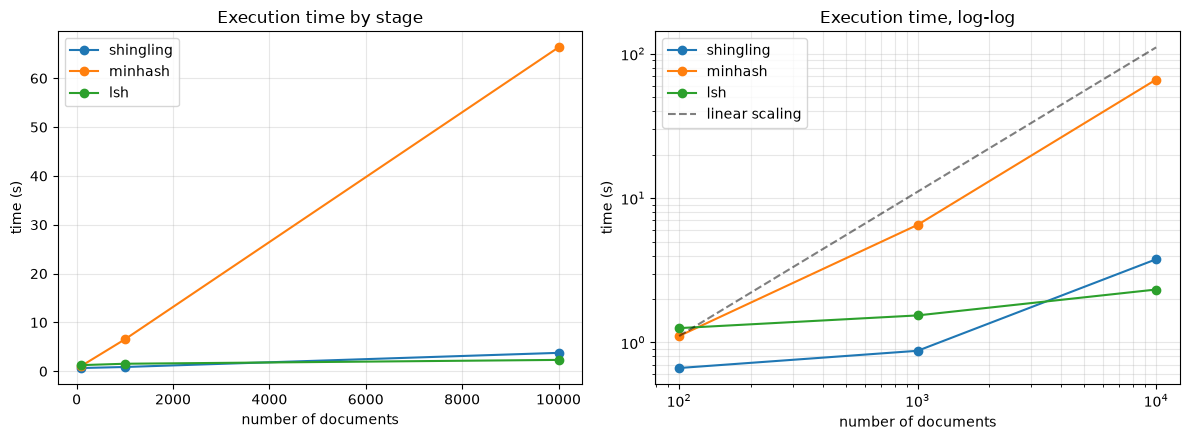

In [15]:
%matplotlib inline
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for stage in ["shingling", "minhash", "lsh"]:
    axes[0].plot(SIZES, [results[n][stage] for n in SIZES], marker="o", label=stage)

axes[0].set(xlabel="number of documents", ylabel="time (s)", title="Execution time by stage")
axes[0].legend()
axes[0].grid(alpha=0.3)

for stage in ["shingling", "minhash", "lsh"]:
    axes[1].loglog(SIZES, [results[n][stage] for n in SIZES], marker="o", label=stage)
    
ref = [results[SIZES[0]]["minhash"] * n / SIZES[0] for n in SIZES]
axes[1].loglog(SIZES, ref, "k--", alpha=0.5, label="linear scaling")

axes[1].set(xlabel="number of documents", ylabel="time (s)", title="Execution time, log-log")
axes[1].legend()
axes[1].grid(alpha=0.3, which="both")

plt.tight_layout()
plt.show()

## Conclusions

The experiments of this laboratory work show that combining shingling, minhashing and locality-sensitive hashing makes it possible to find similar documents almost as accurately as exhaustive comparison, at a fraction of the cost. LSH recovered nearly all of the pairs found by the brute-force baseline. It also introduced no false positives, because every
candidate is verified against the similarity threshold. Its runtime grew roughly linearly with the number of documents, while the baseline grew exponentially and quickly became impractical. One unexpected finding was that the most expensive stage was signature generation, not LSH: computing many hash functions over every shingle in pure Python is costly. Reading the XML directly with Spark, instead of parsing it on the driver and parallelizing afterwards, also made the pipeline cleaner and more scalable.